# 05 - Temporal topic clustering with `ttta`

Uses the [`ttta`](https://github.com/K-RLange/ttta) package (Lange et al., "ttta: Tools for Temporal Text Analysis"):

* **RollingLDA** - an LDA topic model fitted on a warm-up period and then *updated chunk by chunk* (e.g. month by month),
  so topics keep the same meaning over time and their shares can be compared across periods.
* **TopicalChanges** - a bootstrap control chart that flags the chunks in which a topic's word usage changed more than
  random variation would explain, plus the words responsible.

For now the polars corpus is converted to **pandas** (that is what `ttta` expects): one row per post with the *tokenised*
text (list of words) and a date. Install the optional dependency first: `uv sync --group topics`
(`ttta` is GPL-3.0 licensed and beta software - results depend on the settings below, so treat them as exploratory).

Reading guide
* Topics are numbers; **name them yourself** after reading the top words and example posts (`TOPIC_NAMES`).
* Chunks are labelled by their *end* date; period names come from `config/phases.csv`.
* Set `DROP_PATTERN` to remove boilerplate ("Abonniere unseren Kanal ...") before training - see the sampler / regex
  step in the README.

In [1]:
%matplotlib inline
import os, warnings
from datetime import date, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

from tg_ingestor.analysis import *

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

DATA = os.environ.get("TG_DATA", "../storage/raw")            # folder with the exported .csv / .parquet files
FIG = Path(os.environ.get("TG_FIGURES", "../storage/figures"))  # every plot / table is also saved here
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.25})
pl.Config.set_tbl_rows(40).set_tbl_cols(20).set_fmt_str_lengths(70)


def savefig(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

In [2]:
import matplotlib
from ttta.methods.rolling_lda import RollingLDA
from ttta.methods.topical_changes import TopicalChanges

PHASES = load_phases(os.environ.get("TG_PHASES")); EVENTS = load_events(os.environ.get("TG_EVENTS"))
FAST = bool(os.environ.get("TG_TOPIC_FAST"))      # tiny settings for a quick test run

# ---- settings -------------------------------------------------------------------
K = 12                      # number of topics (try 8 / 12 / 20 and compare the top words)
HOW = "ME"                  # chunk length: "ME" = months, "W" = weeks, "QE" = quarters (pandas offset), or a list of dates
WARMUP = 12                 # chunks used to fit the initial model (ttta default is 48 = 4 years of months)
MEMORY = 3                  # chunks of earlier documents re-used when updating
MAX_PER_MONTH = 4000        # random cap of posts per month -> bounded run time (None = all)
MIN_TOKENS = 6              # skip very short posts
DROP_PATTERN = r"abonnier\w*\s+(unseren|den)\s+kanal.*$|tritt\s+(unserem|dem)\s+kanal\s+bei.*$"   # boilerplate lines (regex)
CHANGE_MIXTURE, CHANGE_QUANTILE = 0.5, 0.99     # lower mixture -> more (smaller) change points are flagged
if FAST:
    K, WARMUP, MAX_PER_MONTH, MIN_TOKENS = 6, 12, 300, 3
# ----------------------------------------------------------------------------------
TOPIC_NAMES = {}            # e.g. {0: "COVID measures", 3: "Ukraine war", 7: "Energy prices"} - fill in after step 2

## 1. Corpus (polars -> pandas, tokenised)

In [3]:
df = load_corpus(DATA)
docs = prepare_topic_corpus(df, min_tokens=MIN_TOKENS, max_per_month=MAX_PER_MONTH, drop_pattern=DROP_PATTERN)
print(f"{df.height:,} posts -> {len(docs):,} documents used ({docs['date'].min().date()} .. {docs['date'].max().date()})")
docs.head(3)

869,307 posts -> 314,666 documents used (2020-01-01 .. 2026-10-21)


,channel,id,link,text,date
0,DruschbaFM,27365,https://t.me/DruschbaFM/27365,"[fast, millionen, menschen, versammelten, pro-...",2023-10-28
1,oliverjanich,82313,https://t.me/oliverjanich/82313,"[jährige, schlauer, als, erwachsenen, natürlic...",2021-12-13
2,satellit_de,17579,https://t.me/satellit_de/17579,"[purer, zerstörungswut, ukrainische, militärs,...",2022-10-25


## 2. Fit RollingLDA

This is the slow step (minutes for ~100k documents). `docs` is sorted and chunked in place by `ttta`; the chunk table
below shows which date range and how many documents each chunk covers.

In [4]:
%%time
kw = dict(initial_epochs=30, subsequent_epochs=15, prototype=2) if FAST else dict(initial_epochs=100, subsequent_epochs=50, prototype=10)
roll = RollingLDA(K=K, how=HOW, warmup=WARMUP, memory=MEMORY, seed=1, verbose=0, **kw)
roll.fit(docs.copy(), workers=1, text_column="text", date_column="date")
chunks = roll.chunk_indices.assign(n_docs=lambda d: d["chunk_start"].diff().shift(-1).fillna(len(docs) - d["chunk_start"].iloc[-1]).astype(int))
print(len(chunks), "chunks")
chunks.head()

82 chunks
CPU times: user 12min 45s, sys: 427 ms, total: 12min 45s
Wall time: 12min 45s


,date,chunk_start,memory_start,n_docs
0,2020-01-31,0,0,1524
1,2020-02-29,1524,0,1421
2,2020-03-31,2945,0,1890
3,2020-04-30,4835,0,2025
4,2020-05-31,6860,0,2936


## 3. What are the topics?

In [5]:
top = roll.top_words(number=10)               # DataFrame: one column per topic, words ordered by importance
top.to_csv(FIG / "05_topic_top_words.csv")
top

,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7,Topic 8,Topic 9,Topic 10,Topic 11
0,ecoflow,polizei,nachrichten,impfung,vitamin,the,ukraine,trump,liebe,epoch,euro,deutschland
1,powerstation,uhr,rt-de,covid-,versandkostenfrei,and,russland,biden,mich,times,deutschland,wer
2,gates,sachsen,länge,studie,europaweit,for,russischen,donald,mir,folgt,prozent,menschen
3,strom,berlin,uhr,impfstoff,körper,that,russische,usa,eva,dokumentation,abonniert,kostenlos
4,delta,freie,findest,patienten,bestellen,this,englisch,new,danke,compact,milliarden,warum
5,dank,stadt,livestream,nebenwirkungen,kopp,here,ukrainischen,joe,herman,infos,millionen,denn
6,geräte,straße,vkontakte,menschen,hildegard,are,putin,musk,andreas,artikel,jahr,afd
7,girocode,markt,newsticker,who,einfach,with,ukrainische,us-präsident,grüße,nachrichten,bundesregierung,als
8,bill,folgt,fullhd,geimpft,klicken,you,usa,york,lieben,direkt,spd,politik
9,powerbank,abonniert,russland,impfungen,produkt,channel,web,präsident,leserzuschrift,videos,deutschen,mich


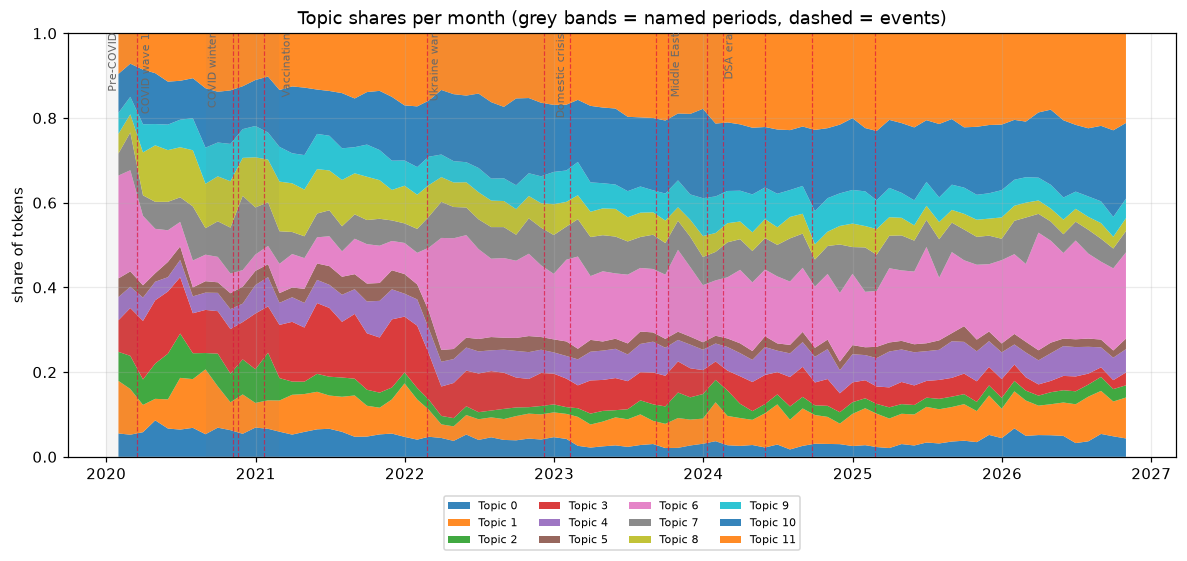

In [6]:
shares = roll.topic_shares(chunk="all")       # rows = chunks (after the warm-up they are the updated models), columns = topics
dates = pd.to_datetime(roll.get_date_of_chunk()["until"]).reset_index(drop=True)
shares.index = dates[:len(shares)] if len(dates) >= len(shares) else dates.reindex(range(len(shares)))
shares = shares.rename(columns=lambda c: TOPIC_NAMES.get(int(str(c).split()[-1]), c))
shares.to_csv(FIG / "05_topic_shares.csv")
fig, ax = plt.subplots(figsize=(13, 5))
ax.stackplot(shares.index, shares.T.to_numpy(), labels=shares.columns, alpha=0.9)
ax.set_ylim(0, 1); ax.set_ylabel("share of tokens"); ax.legend(ncols=4, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.08))
shade_phases(ax, PHASES, label=True); mark_events(ax, EVENTS)
ax.set_title("Topic shares per month (grey bands = named periods, dashed = events)"); savefig("05_topic_shares"); plt.show()

### Topic share per named period

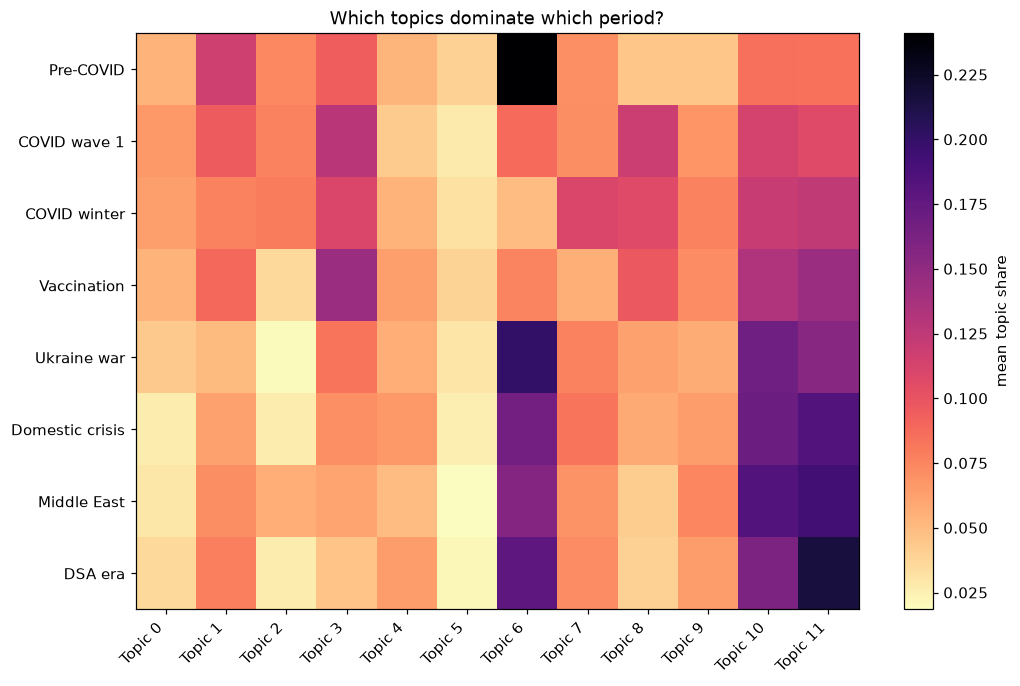

,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7,Topic 8,Topic 9,Topic 10,Topic 11
phase,,,,,,,,,,,,
Pre-COVID,0.054,0.116,0.073,0.094,0.053,0.040,0.241,0.071,0.045,0.045,0.085,0.084
COVID wave 1,0.066,0.096,0.076,0.127,0.042,0.028,0.088,0.071,0.119,0.067,0.113,0.107
COVID winter,0.063,0.076,0.079,0.110,0.054,0.032,0.049,0.110,0.107,0.076,0.120,0.124
Vaccination,0.054,0.088,0.035,0.144,0.063,0.039,0.075,0.055,0.097,0.072,0.133,0.144
Ukraine war,0.043,0.051,0.020,0.082,0.056,0.030,0.200,0.076,0.062,0.057,0.167,0.155
Domestic crisis,0.027,0.062,0.027,0.070,0.066,0.026,0.166,0.082,0.058,0.064,0.169,0.183
Middle East,0.029,0.071,0.056,0.061,0.049,0.018,0.156,0.068,0.042,0.075,0.183,0.193
DSA era,0.035,0.078,0.027,0.046,0.064,0.022,0.177,0.072,0.040,0.064,0.160,0.215


In [7]:
sp = shares.copy()
sp["phase"] = phase_of_dates(sp.index, PHASES)
by_period = sp.dropna(subset=["phase"]).groupby("phase").mean(numeric_only=True)
by_period = by_period.reindex([p for p in PHASES["phase"].to_list() if p in by_period.index])
fig, ax = plt.subplots(figsize=(1 + 0.8 * by_period.shape[1], 0.6 * len(by_period) + 2))
im = ax.imshow(by_period.to_numpy(), cmap="magma_r", aspect="auto"); ax.grid(False)
ax.set_yticks(range(len(by_period)), by_period.index); ax.set_xticks(range(by_period.shape[1]), by_period.columns, rotation=45, ha="right")
plt.colorbar(im, label="mean topic share"); ax.set_title("Which topics dominate which period?"); savefig("05_topic_by_period"); plt.show()
by_period.round(3).to_csv(FIG / "05_topic_by_period.csv"); by_period.round(3)

### Example posts per topic
The documents with the highest share of each topic over the whole period (at least `MIN_LEN` tokens). `ttta` returns
positions in its internal (date-sorted) order; `roll.sorting` maps them back to your rows, so every example comes with
its Telegram link. Read these before naming a topic.

In [8]:
MIN_LEN = 4 if FAST else 12
rows = []
for k in range(K):
    best = roll.get_highest_topic_share(topic=k, chunk=None, number=5, min_length=MIN_LEN)
    for pos, share in best.items():
        r = docs.loc[roll.sorting[pos]]
        rows.append({"topic": TOPIC_NAMES.get(k, f"Topic {k}"), "share": round(float(share), 3), "channel": r["channel"],
                     "date": r["date"].date(), "tokens": " ".join(r["text"][:25]), "link": r["link"]})
examples = pd.DataFrame(rows)
examples.to_csv(FIG / "05_topic_examples.csv", index=False)
examples

,topic,share,channel,date,tokens,link
0,Topic 0,1.0,EvaHermanOffiziell,2020-03-28,leiter malariaabteilung weltgesundheitsorganis...,https://t.me/EvaHermanOffiziell/9050
1,Topic 0,1.0,oliverjanich,2020-04-28,bill-ionaire gates komischer vogel ideen manch...,https://t.me/oliverjanich/25112
2,Topic 0,1.0,EvaHermanOffiziell,2020-05-07,eu-kommissionspräsidentin leyen dankt ländern ...,https://t.me/EvaHermanOffiziell/13508
3,Topic 0,1.0,oliverjanich,2020-05-16,schweizer bundesrat absichtserklärung bill mel...,https://t.me/oliverjanich/26125
4,Topic 0,1.0,kenjebsen,2020-05-17,bill gates sichtlich großen leidenschaft spric...,https://t.me/kenjebsen/255
5,Topic 1,1.0,oliverjanich,2020-01-02,plattling wegen versuchten mordes verurteilter...,https://t.me/oliverjanich/19562
6,Topic 1,1.0,oliverjanich,2020-01-02,cgi hält bedeckt erfuhr sicherheitskreisen kon...,https://t.me/oliverjanich/19557
7,Topic 1,1.0,EvaHermanOffiziell,2020-01-03,linken auge blind unterschiedlich deutschland ...,https://t.me/EvaHermanOffiziell/3408
8,Topic 1,1.0,oliverjanich,2020-01-03,gewalttaten begannen seiten linksextremisten v...,https://t.me/oliverjanich/19636
9,Topic 1,1.0,oliverjanich,2020-01-14,nrw fälle erfasst denen als tatmittel messer e...,https://t.me/oliverjanich/20186


## 4. When did a topic change? (TopicalChanges)

Compares each chunk's word-topic distribution with the preceding `reference_period` chunks and with a **bootstrap**
simulation of what random fluctuation alone would produce. A red mark means: the observed change exceeds the
`quantile_threshold` of the simulation. `mixture` is an a-priori guess of the normal change from one chunk to the next
(lower = more sensitive). Expect several flags in a 6-year corpus; compare them to the events and period boundaries.

In [ ]:
tc = TopicalChanges(roll, mixture=CHANGE_MIXTURE, reference_period=4, quantile_threshold=CHANGE_QUANTILE, samples=100 if FAST else 500)
changes = topical_changes_table(tc, roll)
changes["topic"] = changes["topic"].map(lambda k: TOPIC_NAMES.get(k, f"Topic {k}"))
changes.to_csv(FIG / "05_topical_changes.csv", index=False)
print(f"{len(changes)} (topic, chunk) change points")
changes.sort_values("chunk_end")

In [ ]:
import numpy as np
obs, sim = np.asarray(tc._distances_observed), np.asarray(tc._distances_simulated)
cdates = pd.to_datetime(roll.chunk_indices["date"]).reset_index(drop=True)
w = roll._warmup + 1
ncol = 4; nrow = int(np.ceil(K / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(16, 2.6 * nrow), sharex=True); axs = axs.ravel()
for k in range(K):
    ax = axs[k]; ax.plot(cdates[w:], 1 - obs[w:, k], color="#4575b4", lw=1.2); ax.plot(cdates[w:], 1 - sim[w:, k], color="#db9191", lw=1)
    for i in np.where(sim[w:, k] < obs[w:, k])[0]:
        ax.axvline(cdates[w + i], color="red", ls="--", alpha=0.5)
    ax.set_title(f"{k}: " + ", ".join(top.iloc[:3, k].tolist()), fontsize=8); ax.tick_params(axis="x", rotation=45, labelsize=7)
for ax in axs[K:]: ax.set_visible(False)
fig.suptitle("Similarity to the reference period: observed (blue) vs bootstrap threshold (pink); red = significant change", y=1.0)
plt.tight_layout(); savefig("05_topical_changes"); plt.show()

In [ ]:
impact = tc.word_impact(number=6)     # leave-one-out: which words drive each detected change
impact.to_csv(FIG / "05_change_word_impact.csv", index=False)
impact

### Do the change points line up with the research plan's events and periods?

For each detected change chunk: the nearest event in `config/events.csv` (days apart) and the named period.

In [ ]:
ev = EVENTS.filter(pl.col("date").is_not_null()).select("event", "date").to_pandas()
ev["date"] = pd.to_datetime(ev["date"])
ch = changes.copy()
if len(ch):
    ch["period"] = phase_of_dates(ch["chunk_end"], PHASES)
    def nearest(d):
        diff = (ev["date"] - d).abs(); i = diff.idxmin()
        return pd.Series({"nearest_event": ev.loc[i, "event"], "days_from_event": int((ev.loc[i, "date"] - d).days)})
    out = pd.concat([ch.reset_index(drop=True), ch["chunk_end"].apply(nearest).reset_index(drop=True)], axis=1)
    out.sort_values("chunk_end").assign(chunk_end=lambda d: d["chunk_end"].dt.date).drop(columns=["observed", "threshold"])
else:
    print("no change points - try a lower CHANGE_MIXTURE")

## Notes and cautions
* **Choosing K, chunk length and warm-up is a modelling decision** - run several values and keep what is stable and interpretable
  (topic coherence is not computed here). Fix the choice in your pre-registration, do not tune it to the hypotheses.
* Tokenisation is simple (lower-case, German stop-word list, no lemmatisation); `ttta`'s own `preprocess` pipeline is English-only.
  Inflected forms (Impfung / Impfungen / Impfpflicht) therefore count as separate words.
* `MAX_PER_MONTH` draws a random sample per month, so busy months are under-represented in absolute terms (shares stay comparable).
* A "change" is a change in how words are used *within a topic* relative to the recent past, not in the topic's popularity -
  use the topic-share plot for the latter.
* `ttta.TopicalChanges.plot_distances` forces the TkAgg backend and fails in notebooks / servers, so the plot above is drawn from its distance arrays.

**References.** Lange, K.-R., Schmidt, M., Rieger, J. et al. (2025). *ttta: Tools for Temporal Text Analysis*, arXiv:2503.02625.
Blei, D. M., Ng, A. Y. & Jordan, M. I. (2003). Latent Dirichlet allocation. *J. Machine Learning Research* 3, 993-1022.
Rieger, J., Jentsch, C. & Rahnenfuehrer, J. (2021). RollingLDA: an update algorithm of latent Dirichlet allocation to analyze texts with time stamps
(author list / venue written from memory - check before citing).